**Charger l'ensemble des données**

In [3]:
import json
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

# 1. Chargement des fichiers tabulaires
net_df = pd.read_csv("datasets/network_logs.csv")
sec_df = pd.read_csv("datasets/security_logs.csv")
sys_df = pd.read_csv("datasets/system_metrics.csv")

# Conversion immédiate des colonnes temporelles
net_df["timestamp"] = pd.to_datetime(net_df["timestamp"])
sec_df["timestamp"] = pd.to_datetime(sec_df["timestamp"])
sys_df["timestamp"] = pd.to_datetime(sys_df["timestamp"])

# 2. Lecture du fichier texte des logs applicatifs
with open("datasets/application_logs.txt", "r", encoding="utf-8") as f:
    app_logs_raw = f.readlines()

# 3. Chargement de la configuration JSON
with open("datasets/infrastructure_config.json", "r", encoding="utf-8") as f:
    infra_config = json.load(f)

# 4. Vérification rapide des chargements
print(f"✅ network_logs.csv       : {net_df.shape[0]} lignes, {net_df.shape[1]} colonnes")
print(f"✅ security_logs.csv      : {sec_df.shape[0]} lignes, {sec_df.shape[1]} colonnes")
print(f"✅ system_metrics.csv      : {sys_df.shape[0]} lignes, {sys_df.shape[1]} colonnes")
print(f"✅ application_logs.txt   : {len(app_logs_raw)} lignes de log")
print(f"✅ infrastructure_config  : Clés présentes -> {list(infra_config.keys())}")

✅ network_logs.csv       : 600 lignes, 7 colonnes
✅ security_logs.csv      : 420 lignes, 6 colonnes
✅ system_metrics.csv      : 1080 lignes, 6 colonnes
✅ application_logs.txt   : 500 lignes de log
✅ infrastructure_config  : Clés présentes -> ['organization', 'environment', 'servers', 'services', 'thresholds', 'security_rules', 'notes']


**Vérifier les valeurs manquantes et doublons**

In [4]:
def check_quality(df, name):
    print(f"--- Qualité : {name} ---")
    print(f"Valeurs manquantes :\n{df.isnull().sum()}")
    print(f"Nombre de doublons : {df.duplicated().sum()}\n")

check_quality(net_df, "Réseau (network_logs)")
check_quality(sec_df, "Sécurité (security_logs)")
check_quality(sys_df, "Système (system_metrics)")

--- Qualité : Réseau (network_logs) ---
Valeurs manquantes :
timestamp         0
source_ip         0
destination_ip    0
protocol          0
port              0
status            0
latency_ms        0
dtype: int64
Nombre de doublons : 0

--- Qualité : Sécurité (security_logs) ---
Valeurs manquantes :
timestamp     0
username      0
source_ip     0
event_type    0
status        0
severity      0
dtype: int64
Nombre de doublons : 0

--- Qualité : Système (system_metrics) ---
Valeurs manquantes :
timestamp        0
hostname         0
cpu_usage        0
memory_usage     0
disk_usage       0
process_count    0
dtype: int64
Nombre de doublons : 0



**Analyse des données réseau (network_logs.csv)**

***1.Statistiques & Calculs***

In [5]:
print("=" * 50)
print("ANALYSE DES LOGS RÉSEAU")
print("=" * 50)

# 1. Total des communications
total_comms = len(net_df)
print(f"1. Nombre total de communications : {total_comms}")

# 2. Répartition des protocoles
protocol_counts = net_df["protocol"].value_counts()
protocol_pct = net_df["protocol"].value_counts(normalize=True) * 100
print("\n2. Répartition des protocoles :")
for proto in protocol_counts.index:
    print(
        f"   - {proto}: {protocol_counts[proto]} ({protocol_pct[proto]:.2f}%)"
    )

# 3. Latence moyenne, médiane, min et max
mean_latency = net_df["latency_ms"].mean()
print(f"\n3. Latence moyenne : {mean_latency:.2f} ms")
print(
    f"   (Min: {net_df['latency_ms'].min()} ms | Médiane: {net_df['latency_ms'].median()} ms | Max: {net_df['latency_ms'].max()} ms)"
)

# 4. Statuts des communications
status_counts = net_df["status"].value_counts()
print("\n4. Répartition des statuts de communication :")
print(status_counts)

# 5. Taux d'échec
# On identifie les statuts d'échec (souvent 'failed', 'timeout', ou 'error')
failed_count = net_df[
    net_df["status"].str.lower().isin(["failed", "timeout", "error"])
].shape[0]
failure_rate = (failed_count / total_comms) * 100
print(
    f"\n5. Taux d'échec global : {failure_rate:.2f}% ({failed_count}/{total_comms} requêtes)"
)

# 6. Ports les plus sollicités
top_ports = net_df["port"].value_counts().head(5)
print("\n6. Top 5 des ports les plus utilisés :")
print(top_ports)

ANALYSE DES LOGS RÉSEAU
1. Nombre total de communications : 600

2. Répartition des protocoles :
   - TCP: 454 (75.67%)
   - UDP: 146 (24.33%)

3. Latence moyenne : 62.03 ms
   (Min: 9.4 ms | Médiane: 45.6 ms | Max: 1018.5 ms)

4. Répartition des statuts de communication :
status
OK        579
SLOW       12
FAILED      9
Name: count, dtype: int64

5. Taux d'échec global : 1.50% (9/600 requêtes)

6. Top 5 des ports les plus utilisés :
port
443     156
5432    156
53      146
80      142
Name: count, dtype: int64


***2.Visualisation graphique***

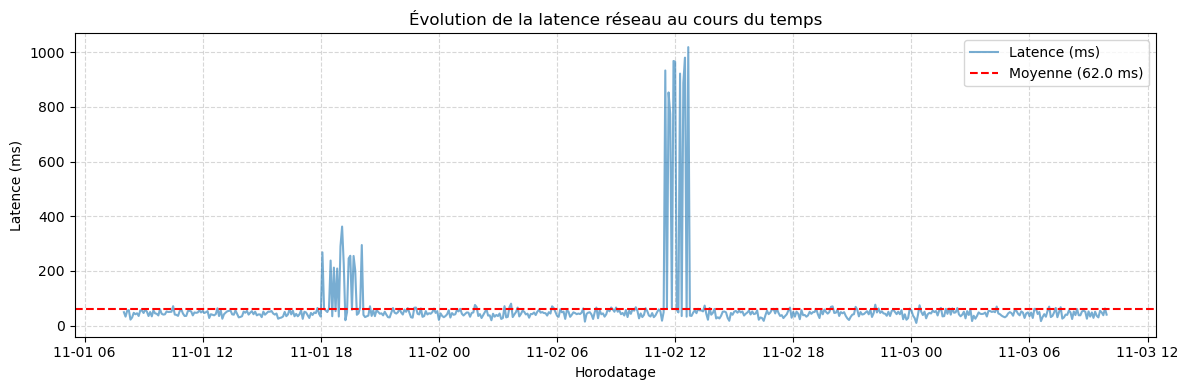

In [9]:
plt.figure(figsize=(12, 4))
plt.plot(
    net_df["timestamp"],
    net_df["latency_ms"],
    color="tab:blue",
    alpha=0.6,
    label="Latence (ms)",
)
plt.axhline(
    mean_latency,
    color="red",
    linestyle="--",
    label=f"Moyenne ({mean_latency:.1f} ms)",
)
plt.title("Évolution de la latence réseau au cours du temps", fontsize=12)
plt.xlabel("Horodatage")
plt.ylabel("Latence (ms)")
plt.legend()
plt.grid(True, linestyle="--", alpha=0.5)
plt.tight_layout()
plt.show()

**Analyse des événements de sécurité (security_logs.csv)**

In [12]:
print("=" * 60)
print("Étape 1.3 : ANALYSE DES ÉVÉNEMENTS DE SÉCURITÉ")
print("=" * 60)

# 1. Nombre d'authentifications réussies et échouées
auth_events = sec_df[sec_df["event_type"].str.contains("auth|login", case=False, na=False)]
# Si tous les événements sont des authentifications ou si on prend toute la colonne status :
status_counts = sec_df["status"].value_counts()
print("1. Authentifications réussies et échouées :")
print(status_counts)
print(f"   -> Réussies (SUCCESS) : {status_counts.get('SUCCESS', 0)}")
print(f"   -> Échouées (FAILED)  : {status_counts.get('FAILED', 0)}")

# 2. Utilisateurs concernés par les échecs
failed_df = sec_df[sec_df["status"].str.upper() == "FAILED"]
users_failed = failed_df["username"].value_counts()
print("\n2. Utilisateurs concernés par les échecs :")
print(users_failed)

# 3. Regroupement des événements par adresse IP source
events_by_ip = sec_df.groupby("source_ip").size().sort_values(ascending=False)
print("\n3. Regroupement de tous les événements par IP source :")
print(events_by_ip)

# 4. Adresses IP associées à plusieurs échecs (> 1 échec)
failed_by_ip = failed_df.groupby("source_ip").size().sort_values(ascending=False)
multiple_failed_ips = failed_by_ip[failed_by_ip > 1]
print("\n4. Adresses IP associées à plusieurs échecs :")
print(multiple_failed_ips)

# 5. Répartition des événements selon leur criticité (severity)
severity_dist = sec_df["severity"].value_counts()
severity_pct = sec_df["severity"].value_counts(normalize=True) * 100
print("\n5. Répartition des événements selon leur criticité :")
for sev in severity_dist.index:
    print(f"   - {sev:8s} : {severity_dist[sev]:3d} ({severity_pct[sev]:.2f}%)")

Étape 1.3 : ANALYSE DES ÉVÉNEMENTS DE SÉCURITÉ
1. Authentifications réussies et échouées :
status
SUCCESS    371
FAILED      49
Name: count, dtype: int64
   -> Réussies (SUCCESS) : 371
   -> Échouées (FAILED)  : 49

2. Utilisateurs concernés par les échecs :
username
admin       14
app_user    13
analyst     10
operator    10
support      2
Name: count, dtype: int64

3. Regroupement de tous les événements par IP source :
source_ip
172.16.0.12     117
192.168.1.51    108
10.0.0.40        97
192.168.1.50     85
203.0.113.77     13
dtype: int64

4. Adresses IP associées à plusieurs échecs :
source_ip
192.168.1.51    14
203.0.113.77    13
10.0.0.40        9
172.16.0.12      9
192.168.1.50     4
dtype: int64

5. Répartition des événements selon leur criticité :
   - INFO     : 371 (88.33%)
   - LOW      :  33 (7.86%)
   - HIGH     :  13 (3.10%)
   - MEDIUM   :   3 (0.71%)


**Analyse des ressources système**

***1.Calculs & Seuils***

In [13]:
print("=" * 60)
print("Étape 1.4 : ANALYSE DES RESSOURCES SYSTÈME")
print("=" * 60)

# 1. Moyenne CPU par serveur
cpu_mean = sys_df.groupby("hostname")["cpu_usage"].mean()
print("1. Utilisation moyenne du CPU par serveur :")
for host, val in cpu_mean.items():
    print(f"   - {host:15s} : {val:.2f}%")

# 2. Moyenne Mémoire par serveur
mem_mean = sys_df.groupby("hostname")["memory_usage"].mean()
print("\n2. Utilisation moyenne de la mémoire par serveur :")
for host, val in mem_mean.items():
    print(f"   - {host:15s} : {val:.2f}%")

# 3. Serveur avec la consommation disque maximale
max_disk_row = sys_df.loc[sys_df["disk_usage"].idxmax()]
print(
    f"\n3. Consommation disque la plus élevée : {max_disk_row['disk_usage']:.2f}%"
)
print(
    f"   -> Serveur concerné : {max_disk_row['hostname']} (le {max_disk_row['timestamp']})"
)

# 4. Extraction des seuils depuis infrastructure_config.json
thresholds = infra_config.get("thresholds", {})
print("\n--- Seuils configurés dans infrastructure_config.json ---")
print(thresholds)

cpu_thresh = thresholds.get("cpu_warning", thresholds.get("cpu_usage", 80))

# 5. Identifier les dépassements de seuil CPU
cpu_breaches = sys_df[sys_df["cpu_usage"] > cpu_thresh]
print(
    f"\n5. Dépassements du seuil CPU (>{cpu_thresh}%) : {len(cpu_breaches)} enregistrements"
)
if len(cpu_breaches) > 0:
    print(
        f"   - Période de début : {cpu_breaches['timestamp'].min()}"
    )
    print(
        f"   - Période de fin   : {cpu_breaches['timestamp'].max()}"
    )
    print(
        "   - Serveurs concernés :",
        list(cpu_breaches["hostname"].unique()),
    )

Étape 1.4 : ANALYSE DES RESSOURCES SYSTÈME
1. Utilisation moyenne du CPU par serveur :
   - app-server-01   : 41.41%
   - db-server-01    : 42.15%
   - web-server-01   : 43.66%

2. Utilisation moyenne de la mémoire par serveur :
   - app-server-01   : 58.58%
   - db-server-01    : 59.94%
   - web-server-01   : 57.25%

3. Consommation disque la plus élevée : 97.20%
   -> Serveur concerné : app-server-01 (le 2026-11-03 17:30:00)

--- Seuils configurés dans infrastructure_config.json ---
{'cpu': 80, 'memory': 85, 'disk': 90, 'latency_ms': 150}

5. Dépassements du seuil CPU (>80%) : 16 enregistrements
   - Période de début : 2026-11-02 05:40:00
   - Période de fin   : 2026-11-02 08:10:00
   - Serveurs concernés : ['web-server-01']


***2.Visualisation de l'utilisation CPU***

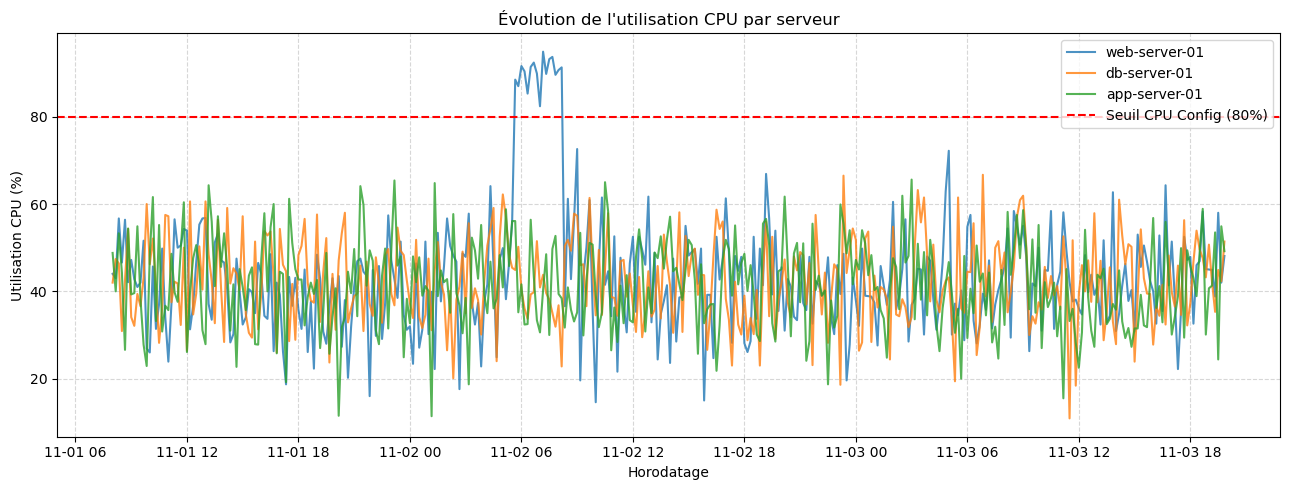

In [14]:
import matplotlib.pyplot as plt

plt.figure(figsize=(13, 5))

# Tracer une courbe par serveur
for host in sys_df["hostname"].unique():
    subset = sys_df[sys_df["hostname"] == host].sort_values(by="timestamp")
    plt.plot(
        subset["timestamp"],
        subset["cpu_usage"],
        label=host,
        alpha=0.8,
        linewidth=1.5,
    )

# Tracer la ligne de seuil de configuration
plt.axhline(
    cpu_thresh,
    color="red",
    linestyle="--",
    label=f"Seuil CPU Config ({cpu_thresh}%)",
)

plt.title("Évolution de l'utilisation CPU par serveur", fontsize=12)
plt.xlabel("Horodatage")
plt.ylabel("Utilisation CPU (%)")
plt.legend(loc="upper right")
plt.grid(True, linestyle="--", alpha=0.5)
plt.tight_layout()
plt.show()

**Analyse des journaux applicatifs (application_logs.txt)**

***1.Parsing Regex & Comptage et représentation graphique***

Étape 1.5 : ANALYSE DES JOURNAUX APPLICATIFS
Total d'enregistrements : 500

1. Répartition par niveau de sévérité :
   - INFO     : 460 (92.00%)
   - ERROR    :  40 (8.00%)

2. Messages d'erreurs les plus fréquents (Total ERROR = 40) :
   [13 fois] Database connection failed
   [ 9 fois] Invalid application configuration
   [ 9 fois] HTTP N Internal Server Error
   [ 6 fois] Request timeout
   [ 3 fois] Connection pool exhausted


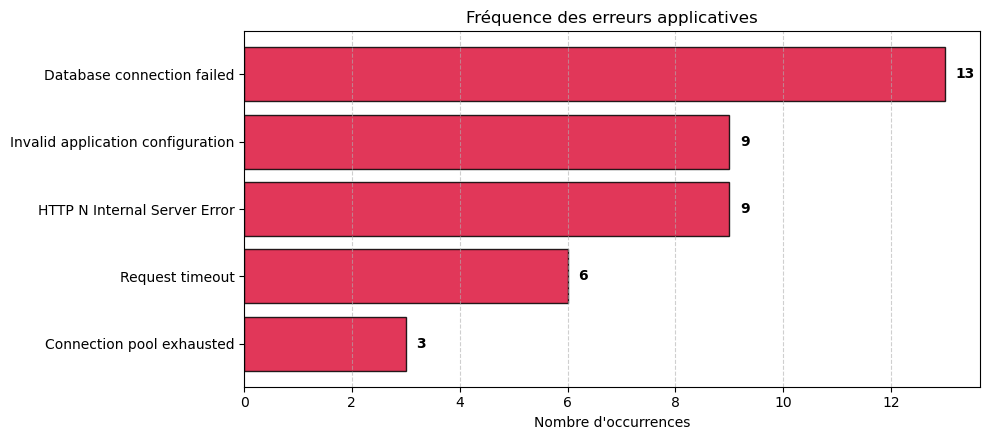

In [18]:
from collections import Counter
import re
import matplotlib.pyplot as plt
import pandas as pd

print("=" * 60)
print("Étape 1.5 : ANALYSE DES JOURNAUX APPLICATIFS")
print("=" * 60)

# 1. Regex de découpage des logs applicatifs
log_pattern = re.compile(
    r"^(?P<timestamp>\d{4}-\d{2}-\d{2}\s\d{2}:\d{2}:\d{2})\s+\[(?P<level>[A-Z]+)\]\s+(?P<message>.*)$"
)

records = []
for line in app_logs_raw:
    l = line.strip()
    if not l:
        continue
    m = log_pattern.match(l)
    if m:
        records.append(m.groupdict())
    else:
        # Fallback si le format a un espacement différent
        parts = l.split(" ", 3)
        if len(parts) >= 4:
            records.append(
                {
                    "timestamp": f"{parts[0]} {parts[1]}",
                    "level": parts[2].strip("[]"),
                    "message": parts[3],
                }
            )

# 2. Création du DataFrame
app_df = pd.DataFrame(records)
app_df["timestamp"] = pd.to_datetime(app_df["timestamp"])

# 3. Comptage par niveau (INFO, WARNING, ERROR)
level_counts = app_df["level"].value_counts()
print(f"Total d'enregistrements : {len(app_df)}")
print("\n1. Répartition par niveau de sévérité :")
for lvl, count in level_counts.items():
    print(f"   - {lvl:8s} : {count:3d} ({count/len(app_df)*100:.2f}%)")

# 4. Filtrage et regroupement des erreurs
errors_df = app_df[app_df["level"] == "ERROR"].copy()

# Normalisation pour regrouper les erreurs similaires (remplace les IDs/chiffres par 'N')
errors_df["error_type"] = errors_df["message"].apply(
    lambda x: re.sub(r"\b\d+\b", "N", x).strip()
)
error_frequencies = errors_df["error_type"].value_counts()

print(
    f"\n2. Messages d'erreurs les plus fréquents (Total ERROR = {len(errors_df)}) :"
)
for err, freq in error_frequencies.items():
    print(f"   [{freq:2d} fois] {err}")

# 5. Graphique de la fréquence des erreurs
plt.figure(figsize=(10, 4.5))
y_pos = range(len(error_frequencies))
plt.barh(
    y_pos,
    error_frequencies.values,
    color="crimson",
    alpha=0.85,
    edgecolor="black",
)
plt.yticks(y_pos, labels=error_frequencies.index, fontsize=10)
plt.gca().invert_yaxis()
plt.xlabel("Nombre d'occurrences")
plt.title("Fréquence des erreurs applicatives", fontsize=12)
plt.grid(axis="x", linestyle="--", alpha=0.6)

for i, v in enumerate(error_frequencies.values):
    plt.text(v + 0.2, i, str(v), va="center", fontweight="bold")

plt.tight_layout()
plt.show()